# 06 · Correlation & error analysis

Where did text features help the model avoid a false market signal, and where did they add noise? Compares the best Model C (by OOF AUC) with Model A of the same family, on test and on the 600 OOF days.

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebook' else None
sys.path.insert(0, os.getcwd())
import pandas as pd
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
FIG = 'report/figures/'
from src.analysis import errors as er, ablation as ab
best = ab.best_per_set()
c = best[best['set'].str.startswith('C_') & (best['set'] != 'C_tuned')].sort_values('oof_roc_auc').iloc[-1]
C_KEY = f"{c['set']}__{c['model']}"; A_KEY = f"A__{c['model']}"
print(C_KEY, 'vs', A_KEY)

C_sentiment__lightgbm vs A__lightgbm


## Outcome counts

In [2]:
for ev in ('oof', 'test'):
    o = er.outcomes(C_KEY, A_KEY, ev)
    print(ev, o['outcome'].value_counts().to_dict())
out = er.outcomes(C_KEY, A_KEY, 'oof')

oof {'both right': 261, 'both wrong': 208, 'text helped': 72, 'text hurt': 59}
test {'both right': 65, 'both wrong': 65, 'text helped': 26, 'text hurt': 20}


## When does text help? (OOF days, terciles)

,by,level,days,helped,hurt,net
0,|move|,small,200,24,20,4
1,|move|,medium,200,24,22,2
2,|move|,large,200,24,17,7
3,news volume,low,200,22,21,1
4,news volume,medium,200,27,16,11
5,news volume,high,200,23,22,1
6,geo news,low,200,19,20,-1
7,geo news,medium,200,27,24,3
8,geo news,high,200,26,15,11


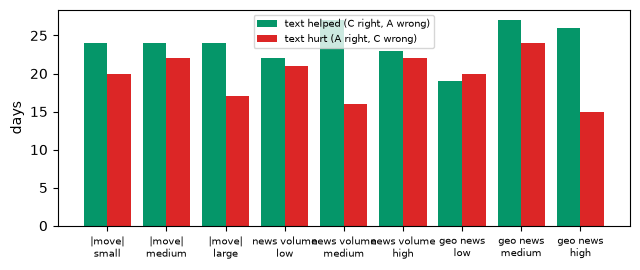

In [3]:
er.breakdown(out, FIG + 'error_breakdown.pdf')

## Examples: largest moves where text helped / hurt

In [4]:
for kind in ('text helped', 'text hurt'):
    ex = er.examples(out, kind, 3)
    print('====', kind)
    for r in ex.itertuples():
        print(r.date, f'ret={r._2}%', f'P_A={r.P_A} P_C={r.P_C}', f'n={r.n_headlines}')
        for h in r.fx_headlines: print('   ', h)

==== text helped
2024-10-07 ret=1.187% P_A=0.345 P_C=0.566 n=240
    Rupiah Dibuka Melemah ke Level Rp15.52, Mayoritas Mata Uang Asia Memerah
    Nasabah Valas Merapat, Cermati Kurs Dollar-Rupiah di Bank Mandiri pada Jumat (4/10)
    RI Deflasi 5 Bulan Beruntun, Begini Tanggapan Sri Mulyani
2023-12-11 ret=0.733% P_A=0.463 P_C=0.573 n=336
    Intip Cara Menukarkan UKA dan Tingkat Kurs Dollar-Rupiah Bank Mandiri, Jumat (8/12)
    Rupiah Akhir Pekan Dibuka Menguat ke Rp15.508, Dolar AS Juga Perkasa
    Dimulainya Megaproyek Baterai RI-China & Tantangan Mendobrak Pasar AS
2024-12-23 ret=-0.685% P_A=0.527 P_C=0.349 n=232
    Cermati Kurs Dollar-Rupiah di Bank Mandiri Hari ini Jumat, 20 Desember 2024
    Rupiah Dibuka Menguat Tipis ke Level Rp16.307 per Dolar AS
    AS Kenakan Tarif Bea Masuk Tinggi ke China, Apa Dampak ke RI?
==== text hurt
2023-11-15 ret=-1.256% P_A=0.49 P_C=0.517 n=223
    Nasabah Valas Merapat, Cek Kurs Dollar-Rupiah di Bank Mandiri Hari Ini Selasa (14/11)
    Hadiri APE

## Correlation of named text features with the same-day return (dev days with news)

,feature,table,rho,p,n
13,e5_ax_dollar_top20,e5_anchors,-0.1211,0.0004,848
12,e5_ax_rupiah_top20,e5_anchors,0.1146,0.0008,848
21,e5_ax_stocks_top20,e5_anchors,0.1105,0.0013,848
18,e5_ax_oil_top20,e5_anchors,-0.0971,0.0047,848
29,usd_dollar,entity_channels,-0.0970,0.0047,848
28,usd_rupiah,entity_channels,0.0967,0.0048,848
45,commodity_dollar,entity_channels,-0.0756,0.0278,848
44,commodity_rupiah,entity_channels,0.0697,0.0425,848
32,idr_rupiah,entity_channels,0.0643,0.0613,848
47,sent_pos_share,sentiment,0.0604,0.0790,848


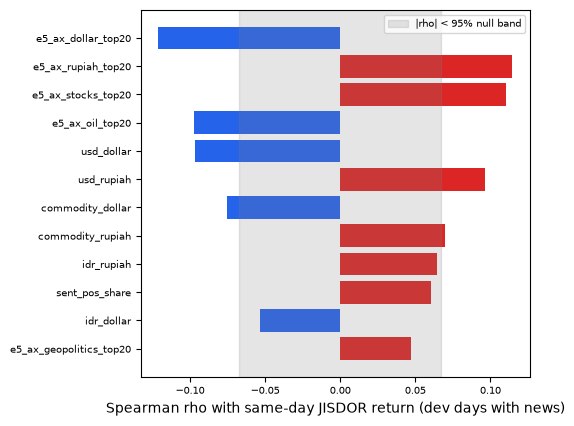

In [5]:
corr = er.feature_correlations(FIG + 'feature_correlations.pdf')
corr.head(15).round(4)